In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from datasets import load_dataset


In [15]:
# Cargar el dataset desde Hugging Face
from datasets import load_dataset

dataset = load_dataset("SIH/palmer-penguins", split="train")

# Convertir los datos a un DataFrame de Pandas
df = dataset.to_pandas()

# Mostrar información del dataset
print("Dataset cargado correctamente")
print("Tamaño del DataFrame:", df.shape)

print("\nColumnas:")
print(df.columns.tolist())

print("\nTipos de datos:")
print(df.dtypes)

print("\nPrimeros cinco registros:")
display(df.head())

Dataset cargado correctamente
Tamaño del DataFrame: (344, 8)

Columnas:
['species', 'island', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex', 'year']

Tipos de datos:
species                  str
island                   str
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
sex                      str
year                   int64
dtype: object

Primeros cinco registros:


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


In [16]:
# Revisar valores nulos
print("VALORES NULOS POR COLUMNA")
print(df.isnull().sum())

# Revisar registros duplicados
print("\nREGISTROS DUPLICADOS")
print(df.duplicated().sum())

# Distribución de las especies
print("\nDISTRIBUCIÓN DE LAS ESPECIES")
print(df["species"].value_counts())

# Estadísticas descriptivas
print("\nESTADÍSTICAS DESCRIPTIVAS")
display(df.describe())

VALORES NULOS POR COLUMNA
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
year                  0
dtype: int64

REGISTROS DUPLICADOS
0

DISTRIBUCIÓN DE LAS ESPECIES
species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

ESTADÍSTICAS DESCRIPTIVAS


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,year
count,342.000000,342.000000,342.000000,342.000000,344.000000
mean,43.921930,17.151170,200.915205,4201.754386,2008.029070
std,5.459584,1.974793,14.061714,801.954536,0.818356
min,32.100000,13.100000,172.000000,2700.000000,2007.000000
25%,39.225000,15.600000,190.000000,3550.000000,2007.000000
50%,44.450000,17.300000,197.000000,4050.000000,2008.000000
75%,48.500000,18.700000,213.000000,4750.000000,2009.000000
max,59.600000,21.500000,231.000000,6300.000000,2009.000000


In [17]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer

# Seleccionar las variables predictoras
columnas = [
    "bill_length_mm",
    "bill_depth_mm",
    "flipper_length_mm",
    "body_mass_g"
]

X = df[columnas]
y = df["species"]

# Dividir los datos en entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Imputar valores faltantes utilizando la mediana
imputador = SimpleImputer(strategy="median")

X_train = pd.DataFrame(
    imputador.fit_transform(X_train),
    columns=columnas,
    index=X_train.index
)

X_test = pd.DataFrame(
    imputador.transform(X_test),
    columns=columnas,
    index=X_test.index
)

# Comprobar el resultado
print("Tamaño de entrenamiento:", X_train.shape)
print("Tamaño de prueba:", X_test.shape)

print("\nValores nulos después del preprocesamiento:")
print(X_train.isnull().sum())

print("\nValores nulos en los datos de prueba:")
print(X_test.isnull().sum())

Tamaño de entrenamiento: (275, 4)
Tamaño de prueba: (69, 4)

Valores nulos después del preprocesamiento:
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
dtype: int64

Valores nulos en los datos de prueba:
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
dtype: int64


In [18]:
from sklearn.tree import DecisionTreeClassifier

# Crear el modelo de árbol de decisión
modelo = DecisionTreeClassifier(random_state=42)

# Entrenar el modelo
modelo.fit(X_train, y_train)

# Realizar predicciones con los datos de prueba
y_pred = modelo.predict(X_test)

# Mostrar algunas predicciones
print("Primeras 10 predicciones:")
print(y_pred[:10])

print("\nPrimeras 10 especies reales:")
print(y_test.iloc[:10].values)

print("\nModelo entrenado correctamente.")

Primeras 10 predicciones:
['Adelie' 'Adelie' 'Gentoo' 'Gentoo' 'Chinstrap' 'Adelie' 'Chinstrap'
 'Gentoo' 'Chinstrap' 'Chinstrap']

Primeras 10 especies reales:
<ArrowStringArray>
[   'Adelie',    'Adelie',    'Gentoo',    'Gentoo', 'Chinstrap',    'Adelie',
 'Chinstrap',    'Gentoo', 'Chinstrap', 'Chinstrap']
Length: 10, dtype: str

Modelo entrenado correctamente.


EXACTITUD DEL MODELO:
0.9855

REPORTE DE CLASIFICACIÓN:
              precision    recall  f1-score   support

      Adelie       1.00      0.97      0.98        30
   Chinstrap       1.00      1.00      1.00        14
      Gentoo       0.96      1.00      0.98        25

    accuracy                           0.99        69
   macro avg       0.99      0.99      0.99        69
weighted avg       0.99      0.99      0.99        69


MATRIZ DE CONFUSIÓN:
[[29  0  1]
 [ 0 14  0]
 [ 0  0 25]]


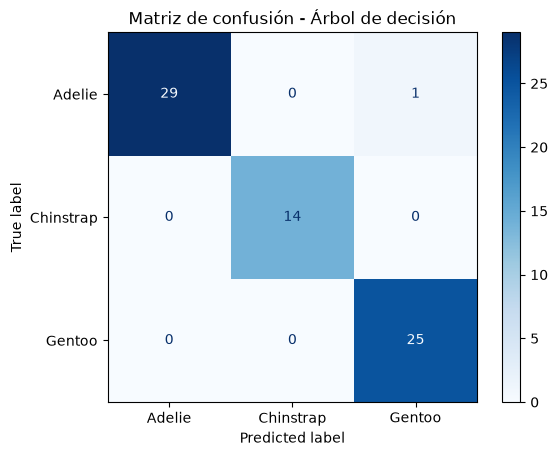

In [19]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Calcular exactitud
exactitud = accuracy_score(y_test, y_pred)

print("EXACTITUD DEL MODELO:")
print(f"{exactitud:.4f}")

# Reporte de clasificación
print("\nREPORTE DE CLASIFICACIÓN:")
print(classification_report(y_test, y_pred))

# Matriz de confusión
matriz = confusion_matrix(y_test, y_pred)

print("\nMATRIZ DE CONFUSIÓN:")
print(matriz)

# Visualizar matriz de confusión
visualizacion = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=modelo.classes_
)

visualizacion.plot(cmap="Blues")
plt.title("Matriz de confusión - Árbol de decisión")
plt.show()

In [20]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier

profundidades = [2, 3, 4, 5, None]

validacion = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

resultados = []

for profundidad in profundidades:
    modelo_prueba = DecisionTreeClassifier(
        max_depth=profundidad,
        random_state=42
    )

    puntuaciones = cross_val_score(
        modelo_prueba,
        X_train,
        y_train,
        cv=validacion,
        scoring="accuracy"
    )

    resultados.append({
        "max_depth": profundidad,
        "exactitud_promedio": puntuaciones.mean(),
        "desviacion": puntuaciones.std()
    })

comparacion = pd.DataFrame(resultados)

display(comparacion)

,max_depth,exactitud_promedio,desviacion
0,2.0,0.952727,0.029542
1,3.0,0.941818,0.035256
2,4.0,0.952727,0.024663
3,5.0,0.952727,0.024663
4,NaN,0.952727,0.024663


In [21]:
modelo_final = DecisionTreeClassifier(
    max_depth=4,
    random_state=42
)

modelo_final.fit(X_train, y_train)

y_pred_final = modelo_final.predict(X_test)

print("Modelo definitivo entrenado.")

Modelo definitivo entrenado.


Vamos a elegir max_depth=4. Tiene la misma exactitud promedio que las profundidades 2, 5 y sin límite, pero presenta menor variabilidad que las profundidades 2 y 3. Además, es más sencillo que dejar el árbol sin límite.

EXACTITUD DEL MODELO DEFINITIVO:
0.9855

REPORTE DE CLASIFICACIÓN:
              precision    recall  f1-score   support

      Adelie       1.00      0.97      0.98        30
   Chinstrap       1.00      1.00      1.00        14
      Gentoo       0.96      1.00      0.98        25

    accuracy                           0.99        69
   macro avg       0.99      0.99      0.99        69
weighted avg       0.99      0.99      0.99        69


MATRIZ DE CONFUSIÓN:
[[29  0  1]
 [ 0 14  0]
 [ 0  0 25]]


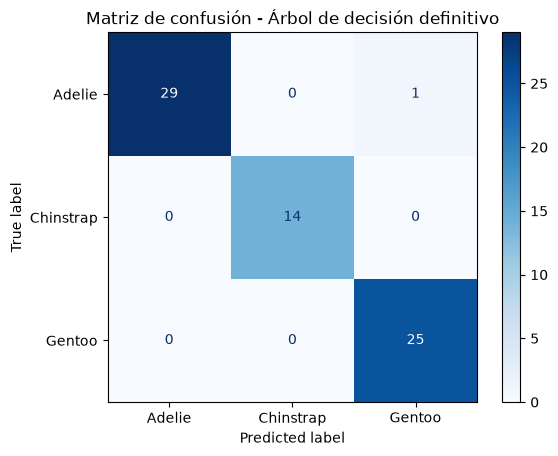

In [22]:
exactitud_final = accuracy_score(y_test, y_pred_final)

print("EXACTITUD DEL MODELO DEFINITIVO:")
print(f"{exactitud_final:.4f}")

print("\nREPORTE DE CLASIFICACIÓN:")
print(classification_report(y_test, y_pred_final))

matriz_final = confusion_matrix(y_test, y_pred_final)

print("\nMATRIZ DE CONFUSIÓN:")
print(matriz_final)

visualizacion = ConfusionMatrixDisplay(
    confusion_matrix=matriz_final,
    display_labels=modelo_final.classes_
)

visualizacion.plot(cmap="Blues")
plt.title("Matriz de confusión - Árbol de decisión definitivo")
plt.show()

,variable,importancia
2,flipper_length_mm,0.539091
0,bill_length_mm,0.354180
1,bill_depth_mm,0.070618
3,body_mass_g,0.036112


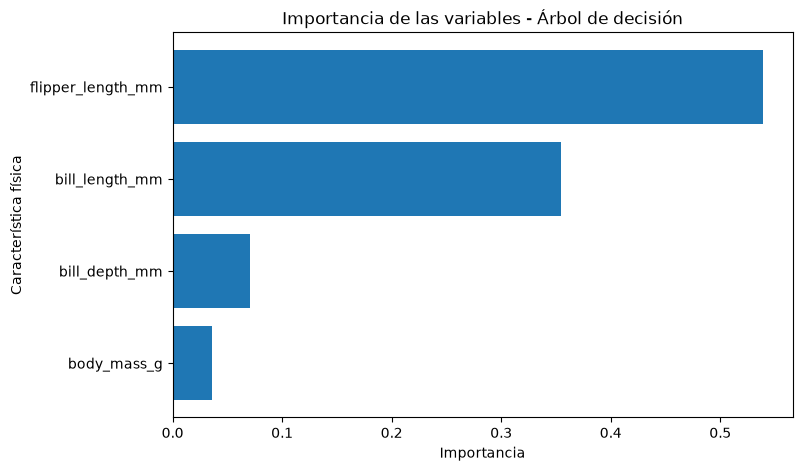

In [23]:
importancia = pd.DataFrame({
    "variable": columnas,
    "importancia": modelo_final.feature_importances_
})

importancia = importancia.sort_values(
    by="importancia",
    ascending=False
)

display(importancia)

plt.figure(figsize=(8, 5))
plt.barh(importancia["variable"], importancia["importancia"])
plt.xlabel("Importancia")
plt.ylabel("Característica física")
plt.title("Importancia de las variables - Árbol de decisión")
plt.gca().invert_yaxis()
plt.show()

Al analizar la importancia de las variables, se encontró que la longitud de las aletas fue la característica que más contribuyó a la clasificación de las especies, con un 53.91 %, seguida por la longitud del pico con un 35.42 %. Por otro lado, la profundidad del pico y la masa corporal tuvieron una menor participación. Esto permite identificar que las características relacionadas con las dimensiones de las aletas y el pico aportaron la mayor información para diferenciar las especies de pingüinos.

In [24]:
from datetime import datetime

with open("resumen_ejecucion.txt", "w", encoding="utf-8") as archivo:

    archivo.write("RESUMEN DE EJECUCION - MACHINE LEARNING\n")
    archivo.write("=" * 45 + "\n\n")

    archivo.write("PREGUNTA DE NEGOCIO:\n")
    archivo.write(
        "¿Es posible identificar la especie de un pingüino "
        "a partir de sus características físicas?\n\n"
    )

    archivo.write("DATASET:\n")
    archivo.write("SIH/palmer-penguins\n")
    archivo.write("Registros: 344\n")
    archivo.write("Columnas: 8\n\n")

    archivo.write("PREPROCESAMIENTO:\n")
    archivo.write("Variables predictoras: " + ", ".join(columnas) + "\n")
    archivo.write("Variable objetivo: species\n")
    archivo.write("Valores nulos: imputados con la mediana\n")
    archivo.write("Duplicados: no se encontraron\n")
    archivo.write("Separacion: 80% entrenamiento y 20% prueba\n\n")

    archivo.write("MODELO:\n")
    archivo.write("Algoritmo: Arbol de decision\n")
    archivo.write("max_depth: 4\n")
    archivo.write("random_state: 42\n\n")

    archivo.write("EVALUACION:\n")
    archivo.write(f"Exactitud: {exactitud_final:.4f}\n")
    archivo.write("\nReporte de clasificacion:\n")
    archivo.write(
        classification_report(y_test, y_pred_final, zero_division=0)
    )

    archivo.write("\nMatriz de confusion:\n")
    archivo.write(str(matriz_final) + "\n\n")

    archivo.write("FECHA DE EJECUCION:\n")
    archivo.write(datetime.now().strftime("%Y-%m-%d %H:%M:%S"))

print("Archivo resumen_ejecucion.txt generado correctamente.")

Archivo resumen_ejecucion.txt generado correctamente.
